In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Mall_Customers.csv")

In [2]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
print(df.isna().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [6]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

df[features].describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


In [7]:
df[features].skew().round(3)

Age                       0.486
Annual Income (k$)        0.322
Spending Score (1-100)   -0.047
dtype: float64

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(df[features])

In [12]:
scaled_df = pd.DataFrame(
    scaled_features,
    columns=features
)

scaled_df.describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


In [13]:
from scipy.cluster.hierarchy import linkage

linkage_matrix = linkage(
    scaled_features,
    method="ward"
)

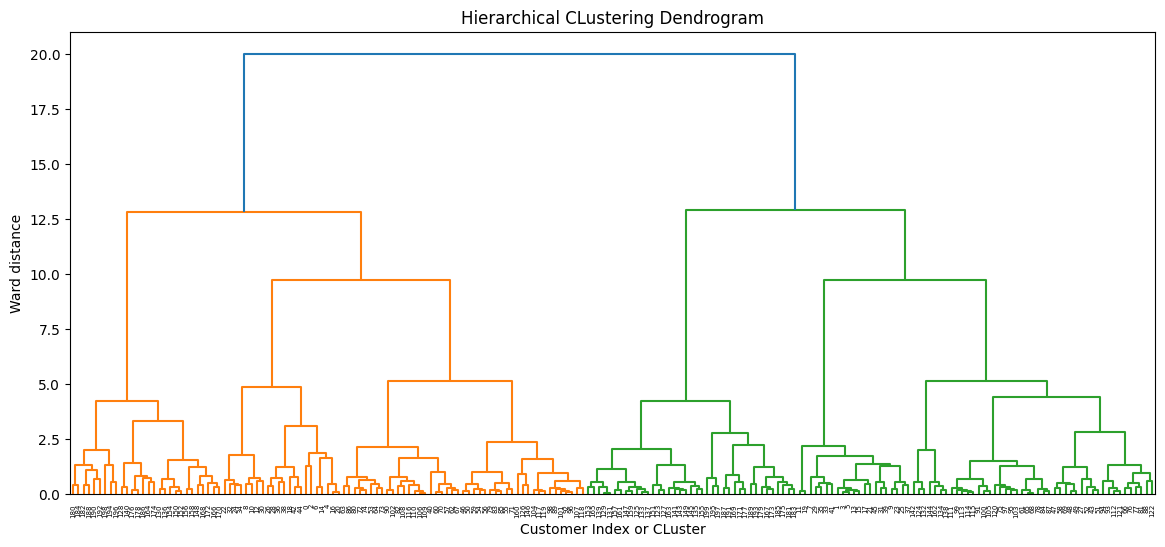

In [16]:
from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(14,6))

dendrogram(linkage_matrix)

plt.title("Hierarchical CLustering Dendrogram")
plt.xlabel("Customer Index or CLuster")
plt.ylabel("Ward distance")
plt.show()

In [17]:
from scipy.cluster.hierarchy import fcluster
import numpy as np

cluster_labels = fcluster(
    linkage_matrix,
    t=15,
    criterion="distance"
)

print("Number of clusters:", len(np.unique(cluster_labels)))

Number of clusters: 2


In [18]:
from scipy.cluster.hierarchy import fcluster
import numpy as np

for distance in [15, 12, 10, 8, 6]:
    labels = fcluster(
        linkage_matrix,
        t=distance,
        criterion="distance"
    )

    print(
        f"Distance: {distance}, "
        f"Clusters: {len(np.unique(labels))}"
    )

Distance: 15, Clusters: 2
Distance: 12, Clusters: 4
Distance: 10, Clusters: 4
Distance: 8, Clusters: 6
Distance: 6, Clusters: 6


In [19]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for k in [2, 3, 4, 5, 6]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels
    )

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.318
K = 3, Silhouette Score = 0.321
K = 4, Silhouette Score = 0.361
K = 5, Silhouette Score = 0.390
K = 6, Silhouette Score = 0.420


In [20]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_model = AgglomerativeClustering(
    n_clusters=6,
    linkage="ward"
)

df["Hierarchical_Cluster"] = (
    hierarchical_model.fit_predict(scaled_features)
)

print(df["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical_Cluster
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


In [21]:
print(
    df.groupby("Hierarchical_Cluster")[
        features
    ].mean().round(2)
)

                        Age  Annual Income (k$)  Spending Score (1-100)
Hierarchical_Cluster                                                   
0                     27.38               57.51                   45.84
1                     56.40               55.29                   48.36
2                     32.69               86.54                   82.13
3                     43.89               91.29                   16.68
4                     44.32               25.77                   20.27
5                     24.81               25.62                   80.24


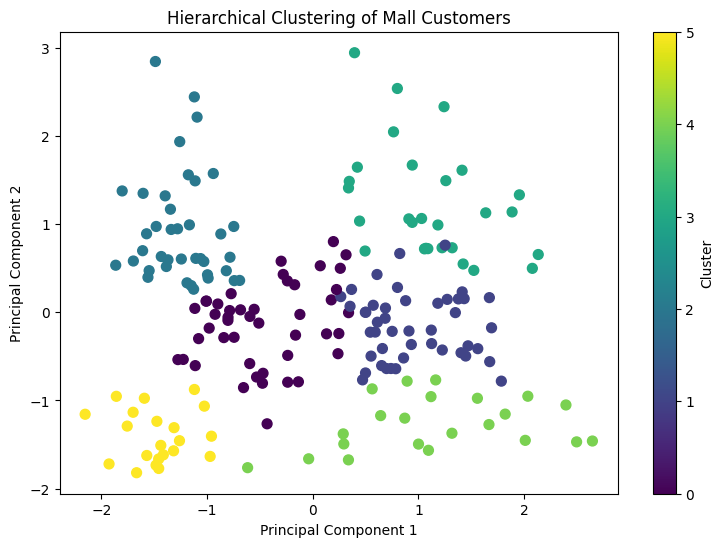

Variance explained: 77.57 %


In [22]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(scaled_features)

plt.figure(figsize=(9, 6))

plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=df["Hierarchical_Cluster"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering of Mall Customers")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)